# Bab 5 — Classification

### Identitas Mahasiswa

| Detail | Identitas |
|---|---|
| Nama | Hadi Nugroho |
| NIM | 101032330235 |

**Tujuan pembelajaran.** memahami naive Bayes, discriminant analysis, dan regresi logistik; membaca koefisien dalam bentuk log-odds dan odds ratio; mengevaluasi classifier dengan confusion matrix, precision, recall, specificity, ROC, AUC, dan lift; mengenal cara menangani kelas yang tidak seimbang.

**Ringkasan bab.** Classification memprediksi kategori, biasanya biner seperti default/paid off. Hampir semua metode di bab ini sebenarnya menghasilkan *peluang* kelas, lalu peluang itu dipotong dengan cutoff menjadi label. Karena itu evaluasi tidak cukup dengan akurasi: kita perlu melihat jenis kesalahan apa yang dibuat model, terutama kalau kelas yang dicari jarang muncul.

Notebook belajar dan reproduksi edisi kedua (Bruce, Bruce, Gedeck, 2020). Penjelasan ditulis ulang dengan bantuan AI; kode diadaptasi dari repository resmi berlisensi GPL-3.0. Bagian tambahan diberi label.

## Setup dan dataset

| File | Unit observasi dan kolom | Catatan |
|---|---|---|
| `loan_data.csv.gz` | 45.342 pinjaman Lending Club; 20 kolom | Sudah diseimbangkan: 22.671 default dan 22.671 paid off. Kolom pertama tanpa header adalah nomor baris asal (1-based) dan dibaca sebagai indeks |
| `loan3000.csv` | 3.000 pinjaman; `borrower_score`, `payment_inc_ratio`, `purpose_` | Subset kecil untuk LDA dan perbandingan batas keputusan |
| `full_train_set.csv.gz` | 119.987 pinjaman; 19 kolom | Data **tidak seimbang** (±18,9% default) untuk bagian imbalanced data |

Kolom penting: `outcome` (default / paid off), `payment_inc_ratio` (rasio cicilan terhadap pendapatan, dalam persen), `borrower_score` (skor 0–1 yang dibuat buku dari KNN, lihat Bab 6), `purpose_`, `home_`, `emp_len_` (kategori tujuan pinjaman, status rumah, lama kerja), serta `dti`, `revol_bal`, `revol_util`.

Kelas positif di seluruh notebook adalah **default**. Urutan kategori `outcome` ditetapkan `['paid off', 'default']` agar kode 1 selalu berarti default.

Sumber file: [repository pendamping edisi kedua](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa/data). Commit sumber dan checksum dicatat di `data/manifest.json`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data/manifest.json").exists():
    raise FileNotFoundError("Buka folder proyek sebagai workspace dan jalankan notebook dari root proyek.")
DATA = ROOT / "data"
SEED = 1
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 110})
pd.set_option("display.max_columns", 25)
print("Python:", sys.version.split()[0], "| Interpreter:", sys.executable)
print("Data:", DATA.relative_to(ROOT))
from sklearn.naive_bayes import MultinomialNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support,
                             roc_curve, roc_auc_score, accuracy_score)
from imblearn.over_sampling import SMOTE, ADASYN
from pygam import LogisticGAM, s
import statsmodels.api as sm
import statsmodels.formula.api as smf

loan_data = pd.read_csv(DATA / 'loan_data.csv.gz', index_col=0)
loan3000 = pd.read_csv(DATA / 'loan3000.csv', index_col=0)
full_train_set = pd.read_csv(DATA / 'full_train_set.csv.gz')
for frame in (loan_data, loan3000, full_train_set):
    frame['outcome'] = pd.Categorical(frame['outcome'], categories=['paid off', 'default'])
for col in ['purpose_', 'home_', 'emp_len_']:
    loan_data[col] = loan_data[col].astype('category')
print('loan_data:', loan_data.shape, '| loan3000:', loan3000.shape, '| full_train_set:', full_train_set.shape)
display(loan_data.outcome.value_counts().rename('jumlah').to_frame().T)
display(full_train_set.outcome.value_counts(normalize=True).rename('proporsi').to_frame().T)
display(loan_data.head())

Python: 3.13.5 | Interpreter: /Users/happhify/Telkom/Machine Learning/Practical-Statistics-for-Data-Scientists/.venv/bin/python
Data: data


loan_data: (45342, 20) | loan3000: (3000, 5) | full_train_set: (119987, 19)


outcome,paid off,default
jumlah,22671,22671


outcome,paid off,default
proporsi,0.811055,0.188945


,status,loan_amnt,term,annual_inc,dti,payment_inc_ratio,revol_bal,revol_util,purpose,home_ownership,delinq_2yrs_zero,pub_rec_zero,open_acc,grade,outcome,emp_length,purpose_,home_,emp_len_,borrower_score
1,Charged Off,2500,60 months,30000,1.00,2.39320,1687,9.4,car,RENT,1,1,3,4.8,default,1,major_purchase,RENT,> 1 Year,0.65
2,Charged Off,5600,60 months,40000,5.55,4.57170,5210,32.6,small_business,OWN,1,1,11,1.4,default,5,small_business,OWN,> 1 Year,0.80
3,Charged Off,5375,60 months,15000,18.08,9.71600,9279,36.5,other,RENT,1,1,2,6.0,default,1,other,RENT,> 1 Year,0.60
4,Charged Off,9000,36 months,30000,10.08,12.21520,10452,91.7,debt_consolidation,RENT,1,1,4,4.2,default,1,debt_consolidation,RENT,> 1 Year,0.50
5,Charged Off,10000,36 months,100000,7.06,3.90888,11997,55.5,other,RENT,1,1,14,5.4,default,4,other,RENT,> 1 Year,0.55


<a id="c5-01"></a>
## Naive Bayes

*Jenis: Teori.*

Naive Bayes memakai teorema Bayes untuk menghitung $P(Y=i \mid X_1,\dots,X_p)$, yaitu peluang sebuah record masuk kelas $i$ jika nilai prediktornya diketahui. Kunci namanya ada di asumsi "naive": di dalam satu kelas, semua prediktor dianggap saling independen. Asumsi ini jarang benar, tapi untuk tujuan *mengurutkan* peluang kelas hasilnya sering tetap cukup baik.

Metode aslinya hanya untuk prediktor kategorikal. Prediktor numerik perlu di-bin atau dimodelkan dengan distribusi tertentu (misalnya normal).

<a id="c5-02"></a>
## Why Exact Bayesian Classification Is Impractical

*Jenis: Teori.*

Versi "exact" mencari semua record yang profil prediktornya **persis sama** dengan record baru, lalu menghitung proporsi kelas di kelompok itu. Masalahnya, jumlah kombinasi kategori tumbuh eksponensial. Dengan 5 prediktor yang masing-masing punya 4 level saja sudah ada $4^5=1024$ profil, dan banyak profil tidak punya satu pun contoh di data. Naive Bayes mengatasi ini dengan tidak mensyaratkan kecocokan penuh, tetapi mengalikan peluang tiap prediktor secara terpisah.

<a id="c5-03"></a>
## The Naive Solution

*Jenis: Reproduksi Python buku + verifikasi manual.*

Untuk setiap kelas: hitung $P(X_j \mid Y=i)$ untuk tiap prediktor, kalikan semuanya, kalikan dengan prior $P(Y=i)$, lalu bagi dengan jumlah hasil semua kelas:

$$P(Y=i\mid X_1,\dots,X_p)=\frac{P(Y=i)\prod_j P(X_j\mid Y=i)}{\sum_k P(Y=k)\prod_j P(X_j\mid Y=k)}$$

Contoh buku memakai tiga prediktor kategorikal (`purpose_`, `home_`, `emp_len_`) dan memprediksi pinjaman baris ke-147. `alpha` dibuat sangat kecil sehingga praktis tanpa Laplace smoothing, dan `fit_prior=False` karena data memang sudah seimbang.

In [2]:
nb_predictors = ['purpose_', 'home_', 'emp_len_']
X_nb = pd.get_dummies(loan_data[nb_predictors], prefix='', prefix_sep='', dtype=int)
y_nb = loan_data['outcome']
naive_model = MultinomialNB(alpha=1e-10, fit_prior=False)
naive_model.fit(X_nb, y_nb)

new_loan = X_nb.loc[[147]]
print('Kategori pinjaman baris 147:', loan_data.loc[147, nb_predictors].tolist())
print('Kelas prediksi:', naive_model.predict(new_loan)[0])
display(pd.DataFrame(naive_model.predict_proba(new_loan), columns=naive_model.classes_, index=['peluang']))

Kategori pinjaman baris 147: ['small_business', 'MORTGAGE', ' > 1 Year']
Kelas prediksi: default


,default,paid off
peluang,0.653699,0.346301


In [3]:
# Hitung ulang secara manual: P(kelas) * produk P(kategori | kelas), lalu normalisasi.
row = loan_data.loc[147, nb_predictors]
manual = {}
for cls in ['paid off', 'default']:
    subset = loan_data[loan_data.outcome == cls]
    likelihood = np.prod([(subset[col] == row[col]).mean() for col in nb_predictors])
    manual[cls] = 0.5 * likelihood          # prior dibuat sama (fit_prior=False)
total = sum(manual.values())
display(pd.Series({k: v / total for k, v in manual.items()}, name='peluang manual').to_frame().T)
cond = (loan_data.groupby('outcome', observed=True)[nb_predictors]
        .apply(lambda g: pd.Series({c: (g[c] == row[c]).mean() for c in nb_predictors})))
display(cond.rename(columns=lambda c: f'P({c}={row[c]} | kelas)'))

,paid off,default
peluang manual,0.346301,0.653699


,P(purpose_=small_business | kelas),P(home_=MORTGAGE | kelas),P(emp_len_= > 1 Year | kelas)
outcome,,,
paid off,0.020996,0.489480,0.968947
default,0.045741,0.431344,0.952715


**Interpretasi dan catatan belajar.** Pinjaman small business dengan status MORTGAGE dan lama kerja > 1 tahun diprediksi **default** dengan peluang ≈0,654, sama dengan hasil buku. Hitungan manual memberi angka yang identik, jadi `MultinomialNB` di sini memang hanya mengalikan proporsi bersyarat. Faktor yang paling menggeser hasil adalah `purpose_`: proporsi small business di kelompok default (≈4,6%) lebih dari dua kali kelompok paid off (≈2,1%). Peluang naive Bayes biasanya terlalu ekstrem karena asumsi independensi, jadi angka ini lebih cocok untuk mengurutkan risiko daripada dibaca sebagai peluang yang terkalibrasi.

<a id="c5-04"></a>
## Numeric Predictor Variables

*Jenis: Padanan Python contoh R buku.*

Untuk prediktor numerik ada dua pilihan: di-bin menjadi kategori, atau diasumsikan mengikuti distribusi tertentu per kelas. Fungsi `NaiveBayes` di R (paket `klaR`) memakai distribusi normal. Scikit-learn tidak menggabungkan keduanya dalam satu model, jadi di sini ditampilkan mean dan standar deviasi `borrower_score` per kelas beserta kurva normalnya.

,mean,std
outcome,,
paid off,0.534793,0.123865
default,0.463220,0.123360


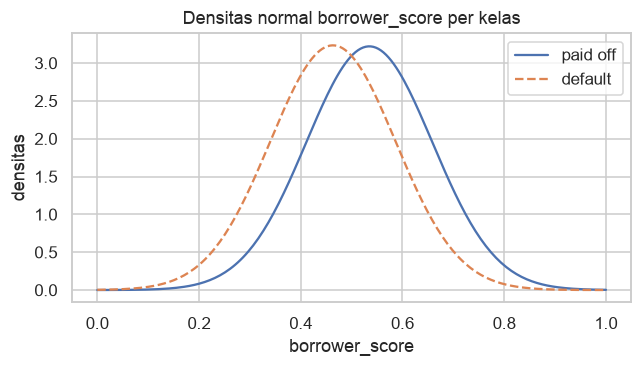

In [4]:
# Prediktor numerik: Gaussian per kelas (yang dilakukan Naive Bayes R untuk kolom numerik).
stats_bs = loan_data.groupby('outcome', observed=True).borrower_score.agg(['mean', 'std'])
display(stats_bs)
from scipy.stats import norm
grid = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(6, 3.5))
for (cls, row_s), style in zip(stats_bs.iterrows(), ['-', '--']):
    ax.plot(grid, norm.pdf(grid, row_s['mean'], row_s['std']), ls=style, label=cls)
ax.set(title='Densitas normal borrower_score per kelas', xlabel='borrower_score', ylabel='densitas')
ax.legend(); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Rata-rata `borrower_score` kelompok default (≈0,463) lebih rendah daripada paid off (≈0,535), tetapi standar deviasinya hampir sama (≈0,124) sehingga kedua kurva banyak tumpang tindih. Artinya skor ini membantu, tapi satu prediktor saja jelas tidak cukup untuk memisahkan dua kelas.

<a id="c5-05"></a>
## Discriminant Analysis

*Jenis: Teori.*

Discriminant analysis adalah classifier statistik paling awal (Fisher, 1936). Yang paling sering dipakai adalah **linear discriminant analysis (LDA)**. Sekarang LDA kalah populer dibanding tree atau regresi logistik, tapi masih dipakai untuk reduksi dimensi dan mudah dihitung.

<a id="c5-06"></a>
## Covariance Matrix

*Jenis: Teori.*

Kovarians mengukur sejauh mana dua variabel bergerak bersama: $s_{x,z}=\frac{\sum_i (x_i-\bar x)(z_i-\bar z)}{n-1}$. Mirip korelasi, tapi skalanya mengikuti satuan variabel. Matriks kovarians $\Sigma$ berisi varians di diagonal dan kovarians antarvariabel di luar diagonal. LDA mengasumsikan setiap kelas punya **matriks kovarians yang sama**; kalau asumsi ini dilepas, hasilnya quadratic discriminant analysis (QDA).

<a id="c5-07"></a>
## Fisher's Linear Discriminant

*Jenis: Teori.*

Fisher mencari kombinasi linear $w_xx+w_zz$ yang membuat jarak antar mean kelas ("between sum of squares", SS_between) sebesar mungkin relatif terhadap sebaran di dalam kelas ("within sum of squares", SS_within). Jadi LDA memaksimalkan rasio SS_between / SS_within. Hasilnya adalah arah proyeksi; record diklasifikasikan berdasarkan sisi mana ia jatuh dari titik tengah kedua kelas.

<a id="c5-08"></a>
## A Simple Example

*Jenis: Reproduksi Python buku.*

LDA dipasang pada `loan3000` dengan dua prediktor numerik. Supaya garis batas bisa digambar, koefisien `scalings_` dan titik tengah dua mean kelas dipakai untuk menurunkan persamaan garis.

In [5]:
lda_predictors = ['borrower_score', 'payment_inc_ratio']
X3 = loan3000[lda_predictors]
y3 = loan3000['outcome']
loan_lda = LinearDiscriminantAnalysis()
loan_lda.fit(X3, y3)
print('Kelas:', list(loan_lda.classes_))
display(pd.DataFrame(loan_lda.scalings_, index=lda_predictors, columns=['LD1']))
display(pd.DataFrame(loan_lda.means_, index=loan_lda.classes_, columns=lda_predictors))
lda_pred = pd.DataFrame(loan_lda.predict_proba(X3), columns=loan_lda.classes_, index=X3.index)
display(lda_pred.head())

Kelas: [np.str_('default'), np.str_('paid off')]


,LD1
borrower_score,7.178232
payment_inc_ratio,-0.099709


,borrower_score,payment_inc_ratio
default,0.462803,8.861813
paid off,0.539068,7.465199


,default,paid off
32109,0.553591,0.446409
16982,0.559004,0.440996
25335,0.272576,0.727424
34580,0.506270,0.493730
14424,0.610035,0.389965


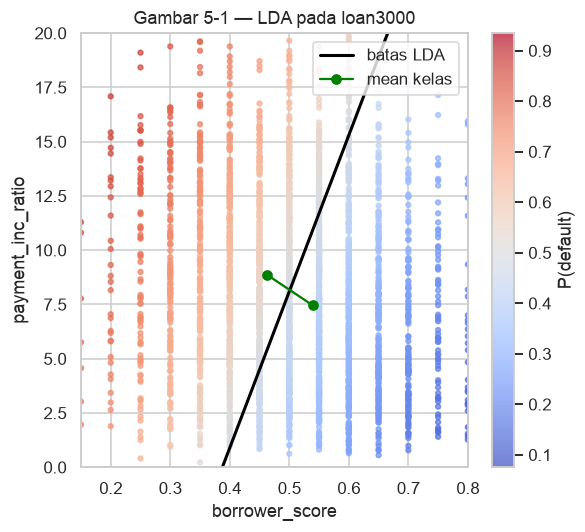

In [6]:
# Garis batas: titik dengan skor diskriminan sama dengan skor di tengah kedua mean kelas.
center = loan_lda.means_.mean(axis=0)
w = loan_lda.scalings_[:, 0]
slope = -w[0] / w[1]
intercept = center[1] - slope * center[0]
xs = np.array([0.15, 0.8])

fig, ax = plt.subplots(figsize=(5.5, 5))
sc = ax.scatter(X3.borrower_score, X3.payment_inc_ratio, c=lda_pred['default'],
                cmap='coolwarm', s=10, alpha=.7)
ax.plot(xs, intercept + slope * xs, color='black', lw=2, label='batas LDA')
ax.plot(*loan_lda.means_.T, 'o-', color='green', label='mean kelas')
ax.set(xlim=(0.15, 0.8), ylim=(0, 20), xlabel='borrower_score', ylabel='payment_inc_ratio',
       title='Gambar 5-1 — LDA pada loan3000')
fig.colorbar(sc, ax=ax, label='P(default)')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Bobot diskriminan ≈7,178 untuk `borrower_score` dan ≈−0,0997 untuk `payment_inc_ratio`, sama dengan output buku. Bobot ini tidak bisa dibandingkan langsung karena skala kedua variabel berbeda jauh (0–1 vs ±0–25). Kelompok default rata-rata punya skor lebih rendah (0,463 vs 0,539) dan rasio cicilan lebih tinggi (8,86 vs 7,47). Pada grafik, titik di kiri atas garis cenderung merah (P(default) tinggi). Makin jauh titik dari garis, makin yakin prediksinya.

<a id="c5-09"></a>
## Logistic Regression

*Jenis: Teori.*

Regresi logistik mirip regresi linear berganda, hanya targetnya biner. Dibanding KNN atau naive Bayes, ia termasuk pendekatan berbasis model struktural: kita menulis persamaan, lalu koefisiennya diestimasi. Kelebihannya cepat dihitung dan mudah diinterpretasi, sehingga sering dipakai di bidang seperti credit scoring.

<a id="c5-10"></a>
## Logistic Response Function and Logit

*Jenis: Reproduksi grafik buku.*

Kalau peluang $p$ dimodelkan langsung sebagai kombinasi linear, hasilnya bisa keluar dari [0, 1]. Solusinya memakai fungsi logistik:

$$p=\frac{1}{1+e^{-(\beta_0+\beta_1x_1+\dots+\beta_qx_q)}}$$

Dengan **odds** $=p/(1-p)$, persamaan bisa ditulis ulang menjadi $\log(\text{odds})=\beta_0+\beta_1x_1+\dots+\beta_qx_q$. Fungsi $\log(p/(1-p))$ disebut **logit**; ia memetakan (0, 1) ke seluruh garis bilangan real, sehingga sisi kanan boleh bernilai berapa saja.

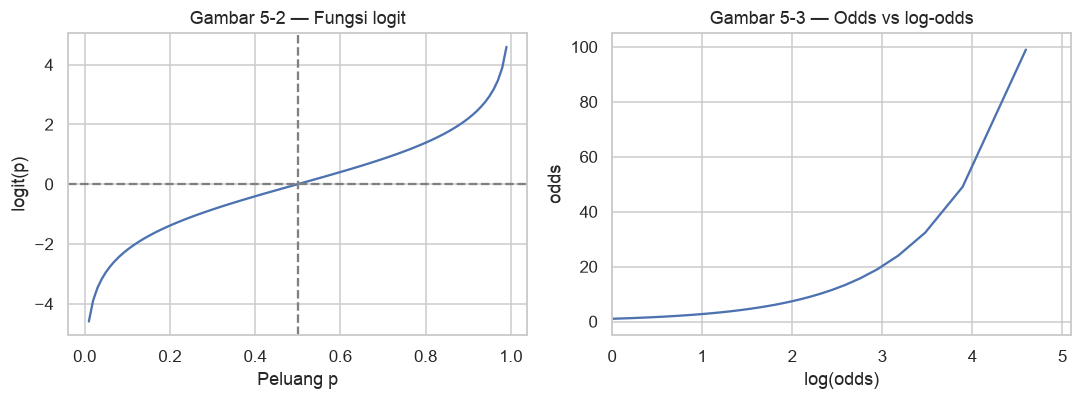

In [7]:
p = np.arange(0.01, 1, 0.01)
logit_df = pd.DataFrame({'p': p, 'odds': p / (1 - p), 'logit': np.log(p / (1 - p))})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(logit_df.p, logit_df.logit)
axes[0].axhline(0, color='grey', ls='--'); axes[0].axvline(.5, color='grey', ls='--')
axes[0].set(title='Gambar 5-2 — Fungsi logit', xlabel='Peluang p', ylabel='logit(p)')
axes[1].plot(logit_df.logit, logit_df.odds)
axes[1].set(title='Gambar 5-3 — Odds vs log-odds', xlabel='log(odds)', ylabel='odds', xlim=(0, 5.1), ylim=(-5, 105))
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Logit bernilai 0 saat p=0,5 dan naik/turun tajam mendekati 1 atau 0. Grafik kanan menunjukkan odds tumbuh eksponensial terhadap log-odds, sehingga perubahan kecil di skala log bisa berarti perubahan odds yang besar.

<a id="c5-11"></a>
## Logistic Regression and the GLM

*Jenis: Reproduksi Python buku; solver diperbarui.*

Model buku memprediksi `outcome` dari `payment_inc_ratio`, `purpose_`, `home_`, `emp_len_`, dan `borrower_score`. Variabel kategori diubah menjadi dummy dengan `drop_first=True` (reference coding). Kode buku memakai `C=1e42` untuk mematikan regularisasi; di scikit-learn versi sekarang cukup `C=np.inf`, dan solver `newton-cholesky` dipakai karena konvergen tanpa harus menskalakan data.

Catatan perbedaan dengan kode buku: buku tidak mengodekan target sehingga scikit-learn memilih kelas kedua secara alfabet (`paid off`) sebagai kelas 1, akibatnya tanda koefisien Python di buku terbalik dibanding R. Di sini target dikodekan eksplisit (`default`=1) sehingga tandanya sama dengan output R.

In [8]:
logit_predictors = ['payment_inc_ratio', 'purpose_', 'home_', 'emp_len_', 'borrower_score']
X_logit = pd.get_dummies(loan_data[logit_predictors], prefix='', prefix_sep='', drop_first=True, dtype=int)
y_logit = loan_data['outcome']
y01 = (y_logit == 'default').astype(int)

# C=np.inf berarti tanpa penalti, setara dengan C=1e42 pada kode buku.
logit_reg = LogisticRegression(C=np.inf, solver='newton-cholesky')
logit_reg.fit(X_logit, y01)
print('Kelas 1 = default | intercept =', round(logit_reg.intercept_[0], 4))
coef_logit = pd.Series(logit_reg.coef_[0], index=X_logit.columns, name='koefisien (log-odds default)')
display(coef_logit.to_frame())
print('Baseline dummy:', loan_data.purpose_.cat.categories[0], '|', loan_data.home_.cat.categories[0],
      '|', loan_data.emp_len_.cat.categories[0])

Kelas 1 = default | intercept = 1.6381


,koefisien (log-odds default)
payment_inc_ratio,0.079736
borrower_score,-4.612624
debt_consolidation,0.249372
home_improvement,0.407741
major_purchase,0.229627
medical,0.510478
other,0.620661
small_business,1.215253
OWN,0.048330
RENT,0.157319


Baseline dummy: credit_card | MORTGAGE |  < 1 Year


**Interpretasi dan catatan belajar.** Koefisien positif menaikkan log-odds default. `payment_inc_ratio` positif (cicilan makin berat → makin berisiko) dan `borrower_score` sangat negatif. Semua kategori `purpose_` positif terhadap baseline credit_card, paling besar small_business. Koefisien dummy selalu dibaca relatif terhadap baseline (credit_card, MORTGAGE, < 1 Year).

<a id="c5-12"></a>
## Generalized Linear Models

*Jenis: Teori.*

GLM terdiri dari dua komponen: **distribusi** target (binomial untuk regresi logistik, Poisson untuk data hitungan, dsb.) dan **link function** yang menghubungkan mean target dengan prediktor linear (logit untuk regresi logistik). Regresi linear biasa adalah GLM dengan distribusi normal dan link identitas. Distribusi lain yang disebut buku: Poisson untuk hitungan, negative binomial, gamma untuk waktu tunggu. Koefisien GLM diestimasi dengan maximum likelihood, bukan least squares.

<a id="c5-13"></a>
## Predicted Values from Logistic Regression

*Jenis: Reproduksi Python buku.*

Output langsung model adalah log-odds $\hat Y=\log(\text{odds})$. Peluang diperoleh dengan fungsi logistik $\hat p=1/(1+e^{-\hat Y})$. Di scikit-learn, `decision_function` memberi log-odds dan `predict_proba` memberi peluang.

In [9]:
pred_logodds = pd.Series(logit_reg.decision_function(X_logit), name='log-odds default')
pred_prob = pd.Series(logit_reg.predict_proba(X_logit)[:, 1], name='P(default)')
display(pd.concat([pred_logodds, pred_prob], axis=1).describe().T)

,count,mean,std,min,25%,50%,75%,max
log-odds default,45342.0,0.002564,0.748928,-2.704766,-0.518823,-0.008539,0.505060,3.509592
P(default),45342.0,0.500000,0.167363,0.062693,0.373127,0.497865,0.623648,0.970959


**Interpretasi dan catatan belajar.** Peluang default hasil prediksi berkisar ≈0,063 sampai ≈0,971 dengan rata-rata 0,500. Rata-rata tepat 0,5 bukan kebetulan: regresi logistik dengan intercept selalu membuat rata-rata peluang prediksi sama dengan proporsi kelas di data latih, dan data ini seimbang 50:50.

<a id="c5-14"></a>
## Interpreting the Coefficients and Odds Ratios

*Jenis: Reproduksi Python buku.*

Odds ratio = $\text{Odds}(Y=1\mid X=1)/\text{Odds}(Y=1\mid X=0)$. Untuk regresi logistik, $\exp(\beta_j)$ adalah odds ratio untuk kenaikan satu unit $X_j$ dengan prediktor lain tetap. Alasan memakai odds ratio, bukan rasio peluang biasa, adalah karena koefisien model memang bekerja di skala log-odds.

In [10]:
odds_ratio = np.exp(coef_logit).rename('odds ratio')
display(pd.concat([coef_logit, odds_ratio], axis=1).sort_values('odds ratio'))
print(f"Kenaikan borrower_score 0,1 poin mengalikan odds default dengan {np.exp(0.1 * coef_logit['borrower_score']):.3f}")

,koefisien (log-odds default),odds ratio
borrower_score,-4.612624,0.009926
> 1 Year,-0.356729,0.699962
OWN,0.048330,1.049517
payment_inc_ratio,0.079736,1.083001
RENT,0.157319,1.170369
major_purchase,0.229627,1.258131
debt_consolidation,0.249372,1.283219
home_improvement,0.407741,1.503418
medical,0.510478,1.666087
other,0.620661,1.860157


Kenaikan borrower_score 0,1 poin mengalikan odds default dengan 0.630


**Interpretasi dan catatan belajar.** Odds default pinjaman small business sekitar 3,37 kali odds pinjaman credit card (prediktor lain sama). Untuk `payment_inc_ratio`, tiap kenaikan 1 poin mengalikan odds dengan ≈1,083. Koefisien `borrower_score` terlihat ekstrem (odds ratio 0,0099) karena "naik satu unit" berarti dari 0 ke 1, seluruh rentang skor. Kenaikan yang lebih realistis, 0,1 poin, mengalikan odds dengan ≈0,63.

<a id="c5-15"></a>
## Linear and Logistic Regression: Similarities and Differences

*Jenis: Teori.*

Persamaannya: keduanya mengasumsikan hubungan linear antara prediktor dan (transformasi) target, dan cara memilih variabel, interaksi, spline, atau pengodean kategori juga sama. Perbedaannya: regresi logistik tidak punya solusi tertutup seperti least squares, jadi koefisien dicari secara iteratif dengan **maximum likelihood estimation (MLE)**. Ukuran fit-nya **deviance** ($-2\log\text{likelihood}$), bukan RSS. Residual juga tidak dibaca sebagai selisih aktual-prediksi biasa karena targetnya 0/1.

<a id="c5-16"></a>
## Assessing the Model

*Jenis: Reproduksi Python buku + perbandingan AIC.*

Ringkasan GLM dari statsmodels memberi standard error, z-value, dan p-value tiap koefisien, mirip `summary()` di R. P-value di sini lebih tepat dipakai sebagai indikator relatif pentingnya variabel daripada uji hipotesis formal. Seperti di regresi linear, hubungan nonlinear bisa ditangkap dengan spline, lalu dicek dengan partial residual plot.

In [11]:
logit_sm = sm.GLM(y01, sm.add_constant(X_logit.astype(float)), family=sm.families.Binomial()).fit()
print(logit_sm.summary())
compare = pd.DataFrame({'sklearn': np.r_[logit_reg.intercept_, logit_reg.coef_[0]],
                        'statsmodels': logit_sm.params.values}, index=logit_sm.params.index)
print('Selisih maksimum koefisien sklearn vs statsmodels:', float((compare.sklearn - compare.statsmodels).abs().max()))

                 Generalized Linear Model Regression Results                  
Dep. Variable:                outcome   No. Observations:                45342
Model:                            GLM   Df Residuals:                    45330
Model Family:                Binomial   Df Model:                           11
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -28757.
Date:                Mon, 19 Oct 2026   Deviance:                       57515.
Time:                        18:10:11   Pearson chi2:                 4.54e+04
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1112
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  1.6381      0

In [12]:
spline_data = loan_data.assign(default=y01)
spline_formula = ('default ~ bs(payment_inc_ratio, df=8) + purpose_ + home_ + emp_len_ '
                  '+ bs(borrower_score, df=3)')
logit_spline = smf.glm(spline_formula, data=spline_data, family=sm.families.Binomial()).fit()
print('Deviance linear:', round(logit_sm.deviance, 1), '| deviance spline:', round(logit_spline.deviance, 1))
print('AIC linear:', round(logit_sm.aic, 1), '| AIC spline:', round(logit_spline.aic, 1))

Deviance linear: 57514.8 | deviance spline: 57462.3
AIC linear: 57538.8 | AIC spline: 57504.3


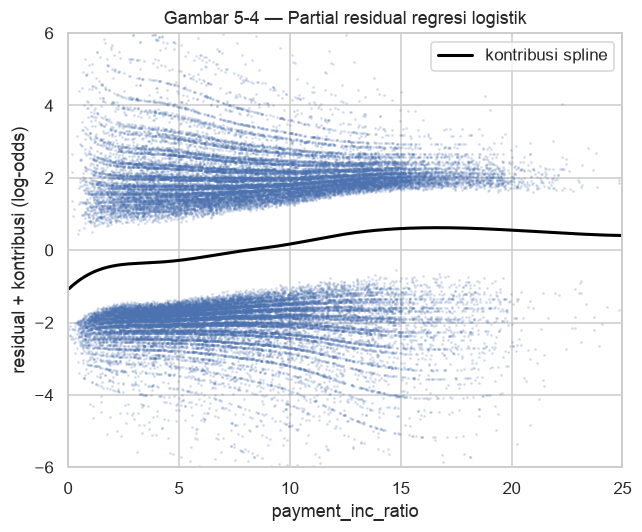

In [13]:
# Partial residual: kontribusi spline payment_inc_ratio pada skala log-odds + residual working.
design = logit_spline.model.exog
names = logit_spline.model.exog_names
cols = [i for i, n in enumerate(names) if 'payment_inc_ratio' in n]
component = design[:, cols] @ logit_spline.params.iloc[cols].to_numpy()
component = component - component.mean()
mu = logit_spline.fittedvalues.to_numpy()
working_resid = (y01.to_numpy() - mu) / (mu * (1 - mu))
partial = working_resid + component
order = np.argsort(loan_data.payment_inc_ratio.to_numpy())

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(loan_data.payment_inc_ratio, partial, s=1, alpha=.15)
ax.plot(loan_data.payment_inc_ratio.to_numpy()[order], component[order], color='black', lw=2, label='kontribusi spline')
ax.set(xlim=(0, 25), ylim=(-6, 6), xlabel='payment_inc_ratio', ylabel='residual + kontribusi (log-odds)',
       title='Gambar 5-4 — Partial residual regresi logistik')
ax.legend(); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Koefisien statsmodels sama dengan scikit-learn (selisih maksimum ~1e-5), dan sama dengan output R buku. Hampir semua p-value sangat kecil karena n=45.342; hanya `OWN` (p≈0,20) yang tidak jelas berbeda dari MORTGAGE. Model spline menurunkan AIC dari ≈57.539 ke ≈57.504, jadi ada sedikit nonlinearitas yang tertangkap.

Partial residual plot regresi logistik terlihat aneh: titik-titik membentuk dua "pita" karena target hanya 0 atau 1. Yang perlu diperhatikan adalah garis hitam: kontribusi `payment_inc_ratio` naik cukup tajam di rasio kecil, terus naik pelan sampai sekitar 15, lalu melandai (sedikit turun) di rasio besar yang datanya sudah jarang. Plot ini dibuat dari matriks desain model (working residual + kontribusi spline), bukan dengan mengubah parameter model seperti helper di kode buku.

<a id="c5-17"></a>
## Evaluating Classification Models

*Jenis: Teori.*

Cara paling sederhana menilai classifier adalah akurasi: proporsi prediksi yang benar. Tapi kebanyakan algoritma menghasilkan peluang, dan label baru muncul setelah peluang dibandingkan dengan **cutoff** (default 0,5). Menurunkan cutoff berarti lebih banyak record diprediksi positif: lebih banyak default tertangkap, tapi juga lebih banyak paid off yang salah dicurigai. Ukuran di bagian-bagian berikut membantu melihat trade-off itu.

Catatan: semua evaluasi di bab ini mengikuti buku dan memakai data latih. Untuk menilai performa sebenarnya, ukuran yang sama harus dihitung di data holdout.

<a id="c5-18"></a>
## Confusion Matrix

*Jenis: Reproduksi Python buku.*

Confusion matrix menyilangkan kelas aktual dan kelas prediksi. Mengikuti buku, baris adalah kelas aktual dan kolom adalah prediksi, dengan default (positif) di posisi pertama.

In [14]:
pred_class = np.where(pred_prob >= 0.5, 'default', 'paid off')
labels = ['default', 'paid off']
conf_mat = pd.DataFrame(confusion_matrix(y_logit.astype(str), pred_class, labels=labels),
                        index=['Y = default', 'Y = paid off'], columns=['Ŷ = default', 'Ŷ = paid off'])
display(conf_mat)
print('Akurasi:', round(accuracy_score(y_logit.astype(str), pred_class), 4))

,Ŷ = default,Ŷ = paid off
Y = default,14336,8335
Y = paid off,8148,14523


Akurasi: 0.6365


**Interpretasi dan catatan belajar.** Diagonal (14.336 dan 14.523) adalah prediksi benar; hasil ini hampir sama dengan tabel buku. Ada 8.335 default yang lolos sebagai paid off (false negative) dan 8.148 paid off yang dicurigai default (false positive). Akurasi 63,6% belum tentu buruk atau baik; tergantung biaya kedua jenis kesalahan tersebut.

<a id="c5-19"></a>
## The Rare Class Problem

*Jenis: Teori.*

Dalam banyak kasus, kelas yang dicari jarang: transaksi fraud, klik iklan, pasien positif. Model yang selalu memprediksi kelas mayoritas bisa punya akurasi 99%, padahal tidak berguna sama sekali. Biasanya kelas langka justru yang paling penting, sehingga kita rela menerima akurasi keseluruhan lebih rendah asalkan kelas itu lebih banyak tertangkap.

<a id="c5-20"></a>
## Precision, Recall, and Specificity

*Jenis: Reproduksi Python buku.*

- **Precision** = TP / (TP + FP): dari yang diprediksi default, berapa yang benar default.
- **Recall / sensitivity** = TP / (TP + FN): dari semua default, berapa yang tertangkap.
- **Specificity** = TN / (TN + FP): dari semua paid off, berapa yang benar dikenali.

In [15]:
cm = conf_mat.to_numpy()
metrics_manual = pd.Series({
    'precision': cm[0, 0] / cm[:, 0].sum(),
    'recall (sensitivity)': cm[0, 0] / cm[0, :].sum(),
    'specificity': cm[1, 1] / cm[1, :].sum(),
})
display(metrics_manual.to_frame('nilai'))
prec, rec, f1, support = precision_recall_fscore_support(y_logit.astype(str), pred_class, labels=labels)
display(pd.DataFrame({'precision': prec, 'recall': rec, 'F1': f1, 'support': support}, index=labels))

,nilai
precision,0.637609
recall (sensitivity),0.632350
specificity,0.640598


,precision,recall,F1,support
default,0.637609,0.632350,0.634968,22671
paid off,0.635357,0.640598,0.637967,22671


**Interpretasi dan catatan belajar.** Precision ≈0,638, recall ≈0,632, specificity ≈0,641. Karena data seimbang dan cutoff 0,5, ketiganya mirip. Pada data tidak seimbang angka-angka ini biasanya sangat berbeda, dan di situ baru terlihat kegunaannya. Hitungan manual dan `precision_recall_fscore_support` memberi hasil yang sama.

<a id="c5-21"></a>
## ROC Curve

*Jenis: Reproduksi Python buku.*

Kurva ROC menggambarkan recall (sumbu y) terhadap specificity (sumbu x, dibalik dari 1 ke 0) untuk semua kemungkinan cutoff. Kurva yang makin dekat ke pojok kiri atas berarti classifier makin baik; garis diagonal adalah tebakan acak.

AUC (roc_auc_score) = 0.6917 | AUC jumlah persegi panjang = 0.6917


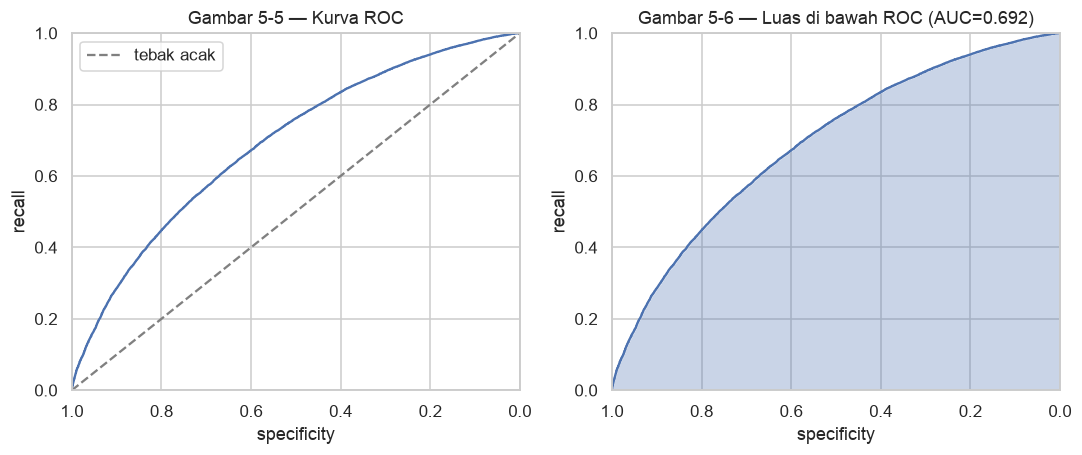

In [16]:
fpr, tpr, thresholds = roc_curve(y01, pred_prob)
roc_df = pd.DataFrame({'recall': tpr, 'specificity': 1 - fpr, 'threshold': thresholds})
auc_trapz = np.sum(roc_df.recall[1:].to_numpy() * np.diff(1 - roc_df.specificity.to_numpy()))
auc = roc_auc_score(y01, pred_prob)
print(f'AUC (roc_auc_score) = {auc:.4f} | AUC jumlah persegi panjang = {auc_trapz:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, shade in zip(axes, [False, True]):
    ax.plot(roc_df.specificity, roc_df.recall)
    ax.set(xlim=(1, 0), ylim=(0, 1), xlabel='specificity', ylabel='recall')
    if shade:
        ax.fill_between(roc_df.specificity, 0, roc_df.recall, alpha=.3)
        ax.set_title(f'Gambar 5-6 — Luas di bawah ROC (AUC={auc:.3f})')
    else:
        ax.plot((1, 0), (0, 1), ls='--', color='grey', label='tebak acak')
        ax.set_title('Gambar 5-5 — Kurva ROC'); ax.legend()
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Kurva berada di atas diagonal tapi masih jauh dari pojok kiri atas. Contohnya, untuk menangkap ±80% default, specificity turun ke sekitar 0,4–0,5, jadi lebih dari separuh paid off ikut dicurigai.

<a id="c5-22"></a>
## AUC

*Jenis: Reproduksi Python buku.*

AUC adalah luas area di bawah kurva ROC (panel kanan di atas). AUC=1 berarti classifier sempurna, 0,5 sama dengan acak. Kode buku menghitungnya dengan menjumlahkan persegi panjang di bawah kurva; hasilnya dibandingkan dengan `roc_auc_score`.

**Interpretasi dan catatan belajar.** AUC ≈0,692, sama untuk kedua cara hitung, dan cocok dengan nilai buku (0,69). Satu tafsiran yang berguna: jika diambil satu pinjaman default dan satu paid off secara acak, peluang model memberi skor risiko lebih tinggi pada yang default adalah ≈69%.

<a id="c5-23"></a>
## Lift

*Jenis: Tambahan Python; konsep dari buku.*

Lift (atau cumulative gains) menjawab pertanyaan praktis: kalau kita hanya bisa memeriksa 10% pinjaman dengan skor risiko tertinggi, seberapa banyak default yang tertangkap dibanding memilih acak? Lift = proporsi default tertangkap / proporsi data yang diambil. Kode resmi Python tidak menyertakan contoh ini, jadi bagian ini dibuat sendiri.

,proporsi data teratas,cumulative gains,lift
0,0.1,0.155750,1.557565
1,0.2,0.295047,1.475298
2,0.3,0.419787,1.399353
3,0.5,0.636231,1.272463


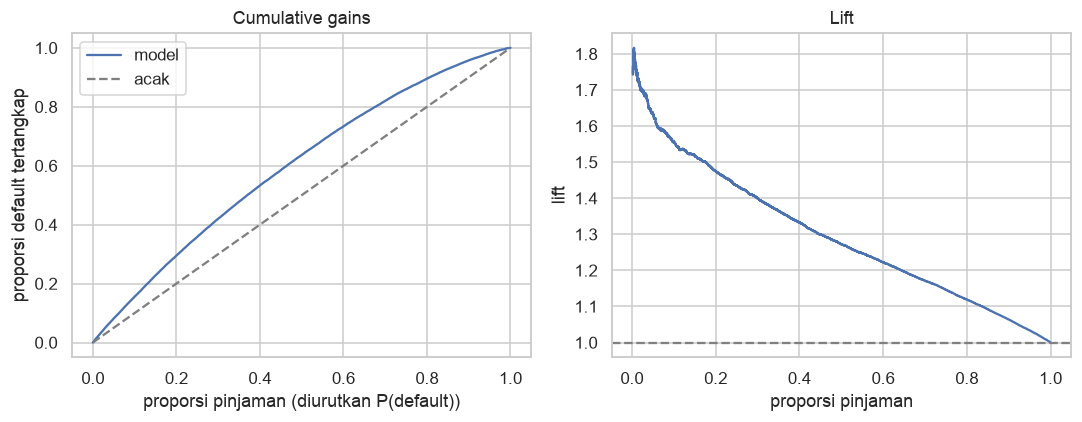

In [17]:
order_idx = np.argsort(-pred_prob.to_numpy())
sorted_y = y01.to_numpy()[order_idx]
frac = np.arange(1, len(sorted_y) + 1) / len(sorted_y)
gains = np.cumsum(sorted_y) / sorted_y.sum()
lift = gains / frac
deciles = pd.DataFrame({'proporsi data teratas': [.1, .2, .3, .5],
                        'cumulative gains': [gains[int(q * len(frac)) - 1] for q in [.1, .2, .3, .5]],
                        'lift': [lift[int(q * len(frac)) - 1] for q in [.1, .2, .3, .5]]})
display(deciles)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(frac, gains, label='model'); axes[0].plot([0, 1], [0, 1], ls='--', color='grey', label='acak')
axes[0].set(title='Cumulative gains', xlabel='proporsi pinjaman (diurutkan P(default))', ylabel='proporsi default tertangkap')
axes[0].legend()
axes[1].plot(frac[100:], lift[100:]); axes[1].axhline(1, ls='--', color='grey')
axes[1].set(title='Lift', xlabel='proporsi pinjaman', ylabel='lift')
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** 10% pinjaman dengan skor tertinggi memuat ≈15,6% dari seluruh default, lift ≈1,56. Lift makin kecil saat porsi yang diambil membesar, dan akan menjadi 1 kalau semua data diambil. Untuk data seimbang lift maksimum hanya 2, jadi grafik ini lebih bermakna di data yang kelas positifnya jarang.

<a id="c5-24"></a>
## Strategies for Imbalanced Data

*Jenis: Teori.*

Bagian ini memakai `full_train_set` yang tidak seimbang (18,9% default). Strateginya: undersampling kelas mayoritas, oversampling atau memberi bobot lebih ke kelas minoritas, membuat data sintetis (SMOTE), atau langsung memasukkan biaya kesalahan ke dalam keputusan.

<a id="c5-25"></a>
## Undersampling

*Jenis: Reproduksi maksud analisis buku.*

Kalau data banyak, kelas mayoritas bisa dikurangi sampai seimbang dengan kelas minoritas. Data `loan_data` di atas sebenarnya hasil cara ini. Di sini model pada data penuh dibandingkan dengan model pada sampel seimbang (semua default + sampel paid off dengan jumlah sama). Kedua model dinilai pada data penuh.

In [18]:
print('Proporsi default di full_train_set: %.2f%%' % (100 * np.mean(full_train_set.outcome == 'default')))
imb_predictors = ['payment_inc_ratio', 'purpose_', 'home_', 'emp_len_', 'dti', 'revol_bal', 'revol_util']
X_full = pd.get_dummies(full_train_set[imb_predictors], prefix='', prefix_sep='', drop_first=True, dtype=int)
y_full = (full_train_set.outcome == 'default').astype(int)

full_model = LogisticRegression(C=np.inf, solver='newton-cholesky')
full_model.fit(X_full, y_full)
pct_full = 100 * full_model.predict(X_full).mean()
print('Prediksi default (data penuh, tidak seimbang): %.2f%%' % pct_full)

# Undersampling: semua default + sampel paid off sebanyak default.
rng = np.random.default_rng(SEED)
idx_def = np.flatnonzero(y_full == 1)
idx_paid = rng.choice(np.flatnonzero(y_full == 0), size=len(idx_def), replace=False)
idx_bal = np.r_[idx_def, idx_paid]
under_model = LogisticRegression(C=np.inf, solver='newton-cholesky').fit(X_full.iloc[idx_bal], y_full.iloc[idx_bal])
pct_under = 100 * under_model.predict(X_full).mean()
print('Prediksi default (model undersampling, dinilai di data penuh): %.2f%%' % pct_under)

Proporsi default di full_train_set: 18.89%
Prediksi default (data penuh, tidak seimbang): 0.39%


Prediksi default (model undersampling, dinilai di data penuh): 42.69%


**Interpretasi dan catatan belajar.** Model pada data penuh hanya memprediksi 0,39% pinjaman sebagai default (buku: 0,39%), padahal aslinya 18,9%. Model hampir selalu memilih paid off karena itu cara termudah untuk akurat. Setelah undersampling, proporsi prediksi default naik ke ≈42,7%. Nilai ini lebih tinggi dari 18,9% karena model belajar dari prior 50:50; kalau dibutuhkan peluang yang sesuai populasi, hasilnya perlu dikalibrasi ulang.

<a id="c5-26"></a>
## Oversampling and Up/Down Weighting

*Jenis: Reproduksi Python buku.*

Alternatif dari membuang data: beri bobot lebih besar pada kelas minoritas. Bobot default dibuat 1/p (p = proporsi default) sehingga total bobot kedua kelas kurang lebih sama. Cara lain adalah oversampling, yaitu menduplikasi record minoritas dengan bootstrap.

In [19]:
default_wt = 1 / np.mean(y_full)
wt = np.where(y_full == 1, default_wt, 1)
print('Bobot kelas default:', round(default_wt, 3))
weighted_model = LogisticRegression(C=np.inf, solver='newton-cholesky').fit(X_full, y_full, sample_weight=wt)
pct_weight = 100 * weighted_model.predict(X_full).mean()
print('Prediksi default (up-weighting): %.2f%%' % pct_weight)

Bobot kelas default: 5.293
Prediksi default (up-weighting): 57.67%


**Interpretasi dan catatan belajar.** Dengan bobot ≈5,29 untuk default, proporsi prediksi default menjadi ≈57,7%, sesuai buku (58%). Hasilnya mirip undersampling, tapi tanpa membuang data paid off.

<a id="c5-27"></a>
## Data Generation

*Jenis: Reproduksi Python buku.*

SMOTE membuat record minoritas sintetis: untuk tiap record default, pilih salah satu tetangga terdekatnya (sesama default), lalu buat titik baru di garis antara keduanya. ADASYN mirip, tetapi lebih banyak membuat sampel di daerah yang sulit diklasifikasikan. Paket `imbalanced-learn` menyediakan keduanya.

In [20]:
rows = [{'metode': 'data penuh', 'proporsi default latih (%)': 100 * y_full.mean(), 'prediksi default (%)': pct_full},
        {'metode': 'undersampling', 'proporsi default latih (%)': 50.0, 'prediksi default (%)': pct_under},
        {'metode': 'up-weighting', 'proporsi default latih (%)': np.nan, 'prediksi default (%)': pct_weight}]
for name, sampler in [('SMOTE', SMOTE(random_state=SEED)), ('ADASYN', ADASYN(random_state=SEED))]:
    X_res, y_res = sampler.fit_resample(X_full, y_full)
    model = LogisticRegression(C=np.inf, solver='newton-cholesky').fit(X_res, y_res)
    rows.append({'metode': name, 'proporsi default latih (%)': 100 * y_res.mean(),
                 'prediksi default (%)': 100 * model.predict(X_full).mean()})
imb_summary = pd.DataFrame(rows).set_index('metode')
display(imb_summary.round(2))

,proporsi default latih (%),prediksi default (%)
metode,,
data penuh,18.89,0.39
undersampling,50.00,42.69
up-weighting,NaN,57.67
SMOTE,50.00,29.29
ADASYN,48.56,27.54


**Interpretasi dan catatan belajar.** Setelah SMOTE/ADASYN, data latih menjadi ±50% default, tetapi model hanya memprediksi ±28–29% default di data penuh, lebih rendah dari undersampling dan weighting. Penyebabnya, SMOTE di sini juga menginterpolasi kolom dummy sehingga muncul nilai pecahan yang tidak realistis. Untuk data campuran numerik-kategorikal, `SMOTENC` lebih tepat. Hasil ini juga sedikit berbeda dari buku karena versi library dan seed.

<a id="c5-28"></a>
## Cost-Based Classification

*Jenis: Teori.*

Dalam praktik, kesalahan punya biaya yang tidak sama. Untuk pinjaman, buku menyarankan membandingkan nilai harapan: $\text{EV}=P(Y=0)\times\text{pendapatan bunga}+P(Y=1)\times\text{kerugian}$. Dengan begitu yang dipilih adalah keputusan dengan keuntungan harapan terbesar, bukan sekadar label default/paid off. Cutoff yang optimal bisa jauh dari 0,5.

<a id="c5-29"></a>
## Exploring the Predictions

*Jenis: Reproduksi Python buku; GAM memakai `LogisticGAM`.*

Satu ukuran (AUC, akurasi) tidak menunjukkan *bagaimana* model mengambil keputusan. Dengan dua prediktor, batas keputusan beberapa model bisa digambar dan dibandingkan langsung. Kode buku memakai `LinearGAM` (regresi kuadrat terkecil pada target 0/1); di sini dipakai `LogisticGAM` agar sesuai dengan model logistik.

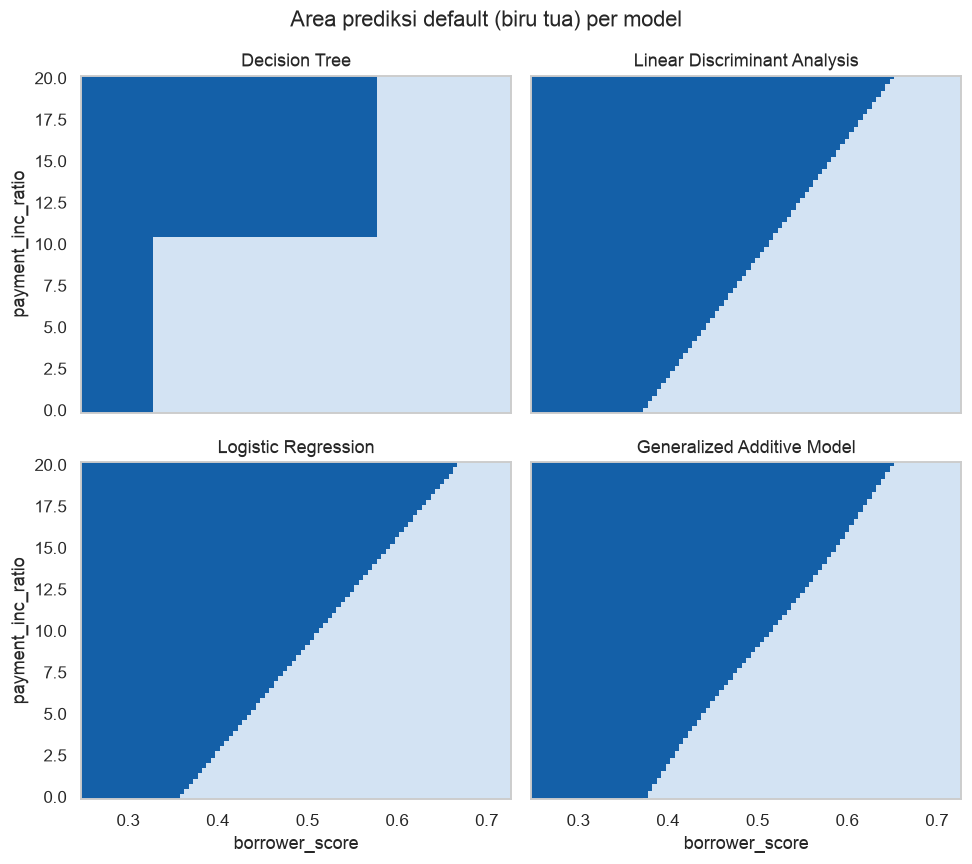

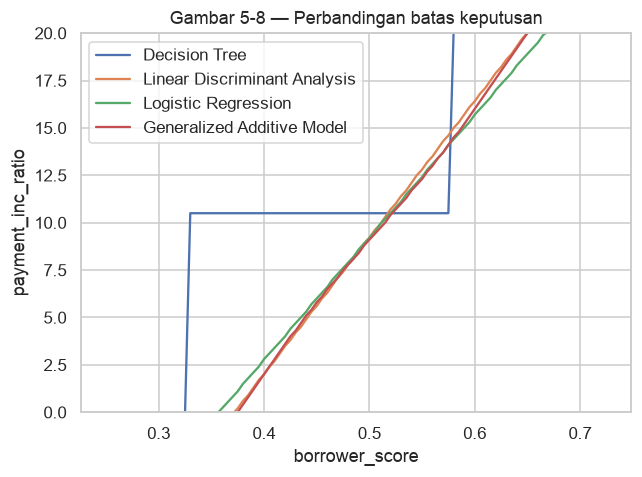

,akurasi latih
Decision Tree,0.611000
Linear Discriminant Analysis,0.629000
Logistic Regression,0.628333
Generalized Additive Model,0.626000


In [21]:
y3_01 = (y3 == 'default').astype(int)
loan_tree = DecisionTreeClassifier(random_state=1, criterion='entropy', min_impurity_decrease=0.003).fit(X3, y3_01)
loan_lda2 = LinearDiscriminantAnalysis().fit(X3, y3_01)
logit_small = LogisticRegression().fit(X3, y3_01)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # pygam memberi RuntimeWarning saat mencoba lambda ekstrem di grid search
    gam = LogisticGAM(s(0) + s(1)).gridsearch(X3.to_numpy(), y3_01.to_numpy(), progress=False)
models = {'Decision Tree': loan_tree, 'Linear Discriminant Analysis': loan_lda2,
          'Logistic Regression': logit_small, 'Generalized Additive Model': gam}

xvalues = np.arange(0.25, 0.73, 0.005)
yvalues = np.arange(-0.1, 20.1, 0.1)
xx, yy = np.meshgrid(xvalues, yvalues)
grid = pd.DataFrame({'borrower_score': xx.ravel(), 'payment_inc_ratio': yy.ravel()})

boundary = {}
fig, axes = plt.subplots(2, 2, figsize=(9, 8), sharex=True, sharey=True)
for ax, (title, model) in zip(axes.flat, models.items()):
    Xg = grid.to_numpy() if title.startswith('Generalized') else grid
    Z = np.asarray(model.predict(Xg)).astype(int).reshape(xx.shape)
    b = yvalues[np.argmax(Z > 0, axis=0)]
    b[Z[-1, :] == 0] = yvalues[-1]
    boundary[title] = b
    ax.pcolormesh(xx, yy, Z, cmap='Blues', vmin=-0.3, vmax=1.3, shading='auto')
    ax.set_title(title)
for ax in axes[1]: ax.set_xlabel('borrower_score')
for ax in axes[:, 0]: ax.set_ylabel('payment_inc_ratio')
fig.suptitle('Area prediksi default (biru tua) per model'); plt.tight_layout(); plt.show()

boundaries = pd.DataFrame(boundary, index=xvalues)
ax = boundaries.plot(figsize=(6, 4.5))
ax.set(ylim=(0, 20), xlabel='borrower_score', ylabel='payment_inc_ratio', title='Gambar 5-8 — Perbandingan batas keputusan')
plt.tight_layout(); plt.show()
display(pd.Series({name: accuracy_score(y3_01, np.asarray(m.predict(X3.to_numpy() if name.startswith('Gen') else X3)).astype(int))
                   for name, m in models.items()}, name='akurasi latih').to_frame())

**Interpretasi dan catatan belajar.** LDA, regresi logistik, dan GAM memberi batas yang hampir berimpit dan hampir lurus; smoothing GAM hasil grid search ternyata tidak menemukan lengkungan berarti. Decision tree berbeda sendiri: batasnya berbentuk tangga karena pohon hanya bisa memotong ruang tegak lurus sumbu. Akurasi latih keempatnya mirip (61–63%), tetapi keputusan untuk pinjaman yang sama bisa berbeda, misalnya pinjaman dengan borrower_score 0,55 dan payment_inc_ratio 11 dianggap default oleh tree tetapi paid off oleh LDA dan regresi logistik.

<a id="c5-30"></a>
## Summary

*Jenis: Teori.*

Naive Bayes, LDA, dan regresi logistik semuanya memprediksi peluang kelas, tetapi dengan asumsi berbeda. Regresi logistik paling banyak dipakai karena koefisiennya bisa dibaca sebagai odds ratio. Pada contoh pinjaman, model logistik mencapai akurasi ≈63,6% dan AUC ≈0,69. Data tidak seimbang membuat model hampir tidak pernah memprediksi default (0,39%); undersampling, weighting, dan SMOTE mengubah perilaku itu, tapi peluang hasilnya perlu dibaca dengan memperhatikan prior yang baru.

**Latihan:** hitung odds ratio untuk kenaikan `payment_inc_ratio` sebesar 5 poin; jelaskan kenapa akurasi tinggi bisa menyesatkan untuk kelas langka; ubah cutoff menjadi 0,3 lalu bandingkan recall dan specificity; ulangi evaluasi bagian Confusion Matrix menggunakan data holdout.

**Batas hasil:** semua ukuran evaluasi mengikuti buku dan dihitung di data latih. Model ini contoh metode, bukan sistem credit scoring yang siap dipakai.

## Referensi dan atribusi

- Peter Bruce, Andrew Bruce, Peter Gedeck. *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, edisi 2, O’Reilly, 2020. ISBN 978-1-492-07294-2, Bab 5.
- [Kode dan dataset resmi pada commit tetap](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa); sumber khusus: `python/code/Chapter 5 - Classification.py`. Copyright kode upstream © 2019 Peter C. Bruce, Andrew Bruce, Peter Gedeck. Modifikasi untuk tugas: penjelasan Indonesia, pengodean target eksplisit, solver baru, partial residual dari matriks desain, contoh lift, dan pengganti fungsi `dmba`. Lisensi GPL-3.0: lihat [LICENSE](LICENSE).
- Dokumentasi [imbalanced-learn](https://imbalanced-learn.org/) untuk SMOTE/ADASYN.

**Refleksi mahasiswa:**